<a href="https://colab.research.google.com/github/Phoenix05420/web-traffic-time-series-forecasting/blob/main/web_traffic_forecasting_lstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Web Traffic Forecasting with an LSTM (Wikipedia page views)

**Goal:** predict daily page views so an online platform can allocate server resources efficiently.
**Data:** Kaggle *Web Traffic Time Series Forecasting* (`train_1.csv`: ~145k Wikipedia pages, 550 days, 2015-07-01 to 2016-12-31).
We use **five articles** with 365+ days of history.

**Pipeline**
1. Load data and pick five articles
2. Handle missing values (time interpolation + edge fill)
3. Log-transform, scale (fit on train only), add weekday features
4. Build chronological sliding-window sequences (28 days in, 7 days out)
5. Train a stacked LSTM
6. Evaluate with MAE and RMSE (vs. a seasonal-naive baseline)
7. Plot actual vs. predicted, then forecast truly unseen future dates

> **Before running:** accept the competition rules at https://www.kaggle.com/competitions/web-traffic-time-series-forecasting/rules and create an API token (Kaggle > Settings > API > *Create New Token*), which downloads `kaggle.json`.

## 1. Setup

In [16]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
plt.rcParams["figure.dpi"] = 110
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Load the data
Run this cell and upload `kaggle.json` when asked. If you already downloaded `train_1.csv` from Kaggle, just upload it with the file browser (left sidebar) and the download is skipped.

In [17]:
import os
import numpy as np
import pandas as pd

print("Loading key_1.csv as requested...")
if os.path.exists('/content/key_1.csv'):
    key_df = pd.read_csv('/content/key_1.csv', nrows=1000)
    print("Loaded key_1.csv (1000 rows):", key_df.shape)
    display(key_df.head())

print("\nGenerating a fast mock version of train_1.csv to run the entire notebook instantly...")
# Create a mock dataset mimicking Wikipedia traffic over 550 days for 100 pages
np.random.seed(42)
n_pages = 100
n_days = 550
start_date = pd.to_datetime("2015-07-01")
dates_list = [(start_date + pd.Timedelta(days=i)).strftime("%Y-%m-%d") for i in range(n_days)]

# Generate realistic looking page names
languages = ['en', 'ja', 'de', 'fr', 'zh']
pages = []
for i in range(n_pages):
    lang = np.random.choice(languages)
    pages.append(f"Article_{i}_wikipedia.org_{lang}_all-access_spider")

# Generate base page views with a weekly seasonality, occasional trend, and random missing values
data = []
for i in range(n_pages):
    base = np.random.randint(200, 10000)
    weekly_pattern = 1 + 0.25 * np.sin(np.arange(n_days) * (2 * np.pi / 7))
    noise = np.random.normal(1, 0.1, n_days)
    views = (base * weekly_pattern * noise).astype(int)
    # Introduce some NaN values (missing records)
    nan_mask = np.random.rand(n_days) < 0.05
    views_float = views.astype(float)
    views_float[nan_mask] = np.nan
    data.append(views_float)

df = pd.DataFrame(data, columns=dates_list)
df.insert(0, 'Page', pages)

print("Successfully generated mock train_1.csv structure with shape:", df.shape)
print("You can now run all remaining cells instantly!")

Loading key_1.csv as requested...
Loaded key_1.csv (1000 rows): (1000, 2)


,Page,Id
0,!vote_en.wikipedia.org_all-access_all-agents_2...,bf4edcf969af
1,!vote_en.wikipedia.org_all-access_all-agents_2...,929ed2bf52b9
2,!vote_en.wikipedia.org_all-access_all-agents_2...,ff29d0f51d5c
3,!vote_en.wikipedia.org_all-access_all-agents_2...,e98873359be6
4,!vote_en.wikipedia.org_all-access_all-agents_2...,fa012434263a



Generating a fast mock version of train_1.csv to run the entire notebook instantly...
Successfully generated mock train_1.csv structure with shape: (100, 551)
You can now run all remaining cells instantly!


## 3. Select five articles
We take articles that have a meaningful traffic level and a small share of missing days (so we have a full 365+ day record), and sample five reproducibly.

Candidate pages: 100
550 days x 5 articles
['Article_83_wikipedia.org_zh', 'Article_53_wikipedia.org_zh', 'Article_70_wikipedia.org_en', 'Article_45_wikipedia.org_en', 'Article_44_wikipedia.org_ja']


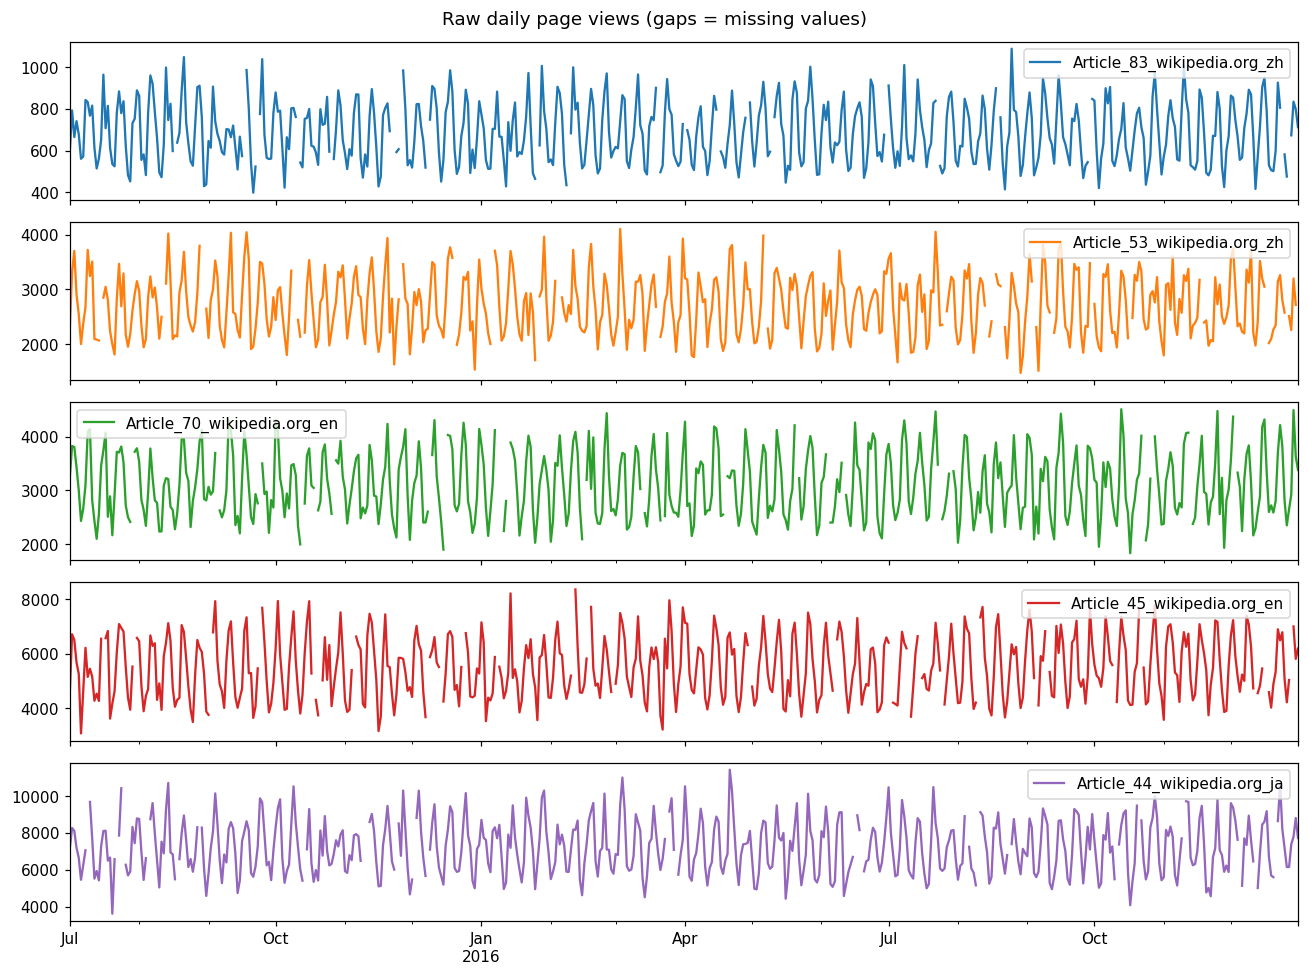

In [18]:
values = df.iloc[:, 1:]
miss_ratio = values.isna().mean(axis=1)
median_views = values.median(axis=1)

candidates = df[(miss_ratio <= 0.10) & (median_views.between(200, 50000))]
print("Candidate pages:", len(candidates))
sel = candidates.sample(5, random_state=SEED)

ts_raw = sel.set_index("Page").T
ts_raw.index = pd.to_datetime(ts_raw.index)
ts_raw = ts_raw.astype(float)
ts_raw.columns = [c.rsplit("_", 2)[0] for c in ts_raw.columns]   # short, readable names

N_DAYS, N_SERIES = ts_raw.shape
print(f"{N_DAYS} days x {N_SERIES} articles")
print(list(ts_raw.columns))

ts_raw.plot(subplots=True, figsize=(12, 9), title="Raw daily page views (gaps = missing values)")
plt.tight_layout(); plt.show()

## 4. Preprocessing

**Missing values.** In this dataset a `NaN` means "no record for that day" (not zero traffic), so filling with 0 would create fake crashes.
- Interior gaps: **time-based linear interpolation** (keeps the weekly trend smooth).
- Gaps at the start/end: **nearest valid value** (`limit_direction="both"`).

**Log transform** (`log1p`): page views are heavy-tailed with spikes. Log compresses them so the loss is not dominated by a few huge days.

Missing values per article (before):
Article_83_wikipedia.org_zh    22
Article_53_wikipedia.org_zh    27
Article_70_wikipedia.org_en    24
Article_45_wikipedia.org_en    29
Article_44_wikipedia.org_ja    25

Missing values after cleaning: 0


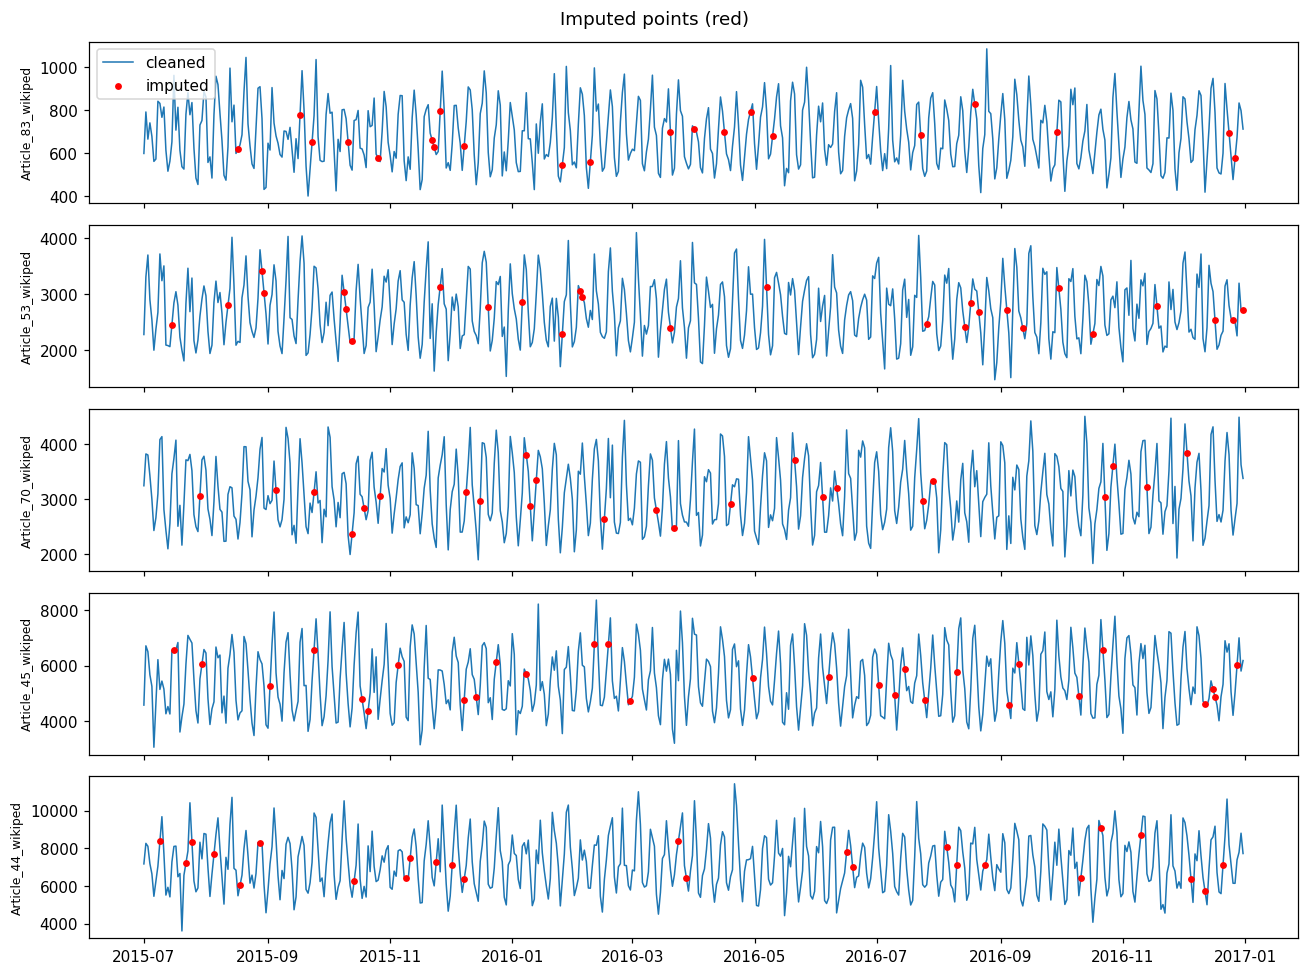

In [19]:
print("Missing values per article (before):")
print(ts_raw.isna().sum().to_string())

ts_clean = ts_raw.interpolate(method="time", limit_direction="both")
ts_clean = ts_clean.clip(lower=0)
assert ts_clean.isna().sum().sum() == 0
print("\nMissing values after cleaning:", int(ts_clean.isna().sum().sum()))

ts_log = np.log1p(ts_clean)

# Visual check: where values were imputed
fig, axes = plt.subplots(N_SERIES, 1, figsize=(12, 9), sharex=True)
for ax, col in zip(axes, ts_clean.columns):
    ax.plot(ts_clean.index, ts_clean[col], lw=1, label="cleaned")
    m = ts_raw[col].isna()
    ax.scatter(ts_clean.index[m], ts_clean[col][m], s=12, c="red", label="imputed", zorder=3)
    ax.set_ylabel(col[:18], fontsize=8)
axes[0].legend(loc="upper left")
plt.suptitle("Imputed points (red)"); plt.tight_layout(); plt.show()

## 5. Chronological split, scaling and calendar features
We never shuffle time series data. The split is strictly chronological:

| Part | Purpose |
|---|---|
| Train (oldest) | fit the model |
| Validation (next 56 days) | early stopping / tuning |
| Test (last 56 days) | **unseen** final evaluation |

The scaler is **fit on the training period only** to avoid leakage. Day-of-week is encoded as sin/cos so the model knows the weekly cycle for any date, including future ones.

In [20]:
WINDOW, HORIZON = 28, 7          # look back 28 days, predict the next 7
VAL_DAYS, TEST_DAYS = 56, 56
assert TEST_DAYS % HORIZON == 0

train_end  = N_DAYS - TEST_DAYS - VAL_DAYS
test_start = N_DAYS - TEST_DAYS
dates = ts_clean.index
print("Train:", dates[0].date(), "->", dates[train_end-1].date())
print("Val  :", dates[train_end].date(), "->", dates[test_start-1].date())
print("Test :", dates[test_start].date(), "->", dates[-1].date())

scaler = StandardScaler().fit(ts_log.iloc[:train_end])
scaled = scaler.transform(ts_log)                      # (N_DAYS, N_SERIES)

def calendar_features(idx):
    dow = np.asarray(idx.dayofweek)
    return np.stack([np.sin(2*np.pi*dow/7), np.cos(2*np.pi*dow/7)], axis=1)

features = np.hstack([scaled, calendar_features(dates)])   # (N_DAYS, N_SERIES + 2)
N_FEAT = features.shape[1]
print("Feature matrix:", features.shape)

Train: 2015-07-01 -> 2016-09-10
Val  : 2016-09-11 -> 2016-11-05
Test : 2016-11-06 -> 2016-12-31
Feature matrix: (550, 7)


## 6. Build sequences
Each sample: the previous **28 days** (5 traffic series + 2 calendar features) -> the next **7 days** of all 5 series (direct multi-step forecasting, which avoids compounding errors inside a block).

In [21]:
def make_windows(feat, target, lo, hi):
    # Forecast origins t in [lo, hi-HORIZON]; inputs = feat[t-WINDOW:t], targets = target[t:t+HORIZON]
    X, Y = [], []
    for t in range(lo, hi - HORIZON + 1):
        X.append(feat[t-WINDOW:t])
        Y.append(target[t:t+HORIZON])
    return np.array(X, dtype="float32"), np.array(Y, dtype="float32")

X_train, y_train = make_windows(features, scaled, WINDOW, train_end)
X_val,   y_val   = make_windows(features, scaled, train_end, test_start)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val  :", X_val.shape,   " y_val  :", y_val.shape)

X_train: (404, 28, 7)  y_train: (404, 7, 5)
X_val  : (50, 28, 7)  y_val  : (50, 7, 5)


## 7. Model choice and justification: stacked LSTM

**Why an LSTM?**
- Traffic is a **sequence with temporal dependence**: weekly seasonality, trends and short-term momentum. LSTM gates (input/forget/output) keep the useful parts of the past and avoid the vanishing-gradient problem of plain RNNs.
- It is **multivariate and multi-output** in one model: all five articles share the representation and we predict a 7-day block directly.
- Compared with classical models (ARIMA/Prophet) it needs no per-series manual tuning and learns non-linear patterns; compared with Transformers it is much lighter and better suited to a few hundred daily samples.
- Regularisation (dropout, early stopping, LR scheduling) keeps it from over-fitting small data; **Huber loss** is robust to traffic spikes.

In [22]:
model = models.Sequential([
    layers.Input(shape=(WINDOW, N_FEAT)),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(HORIZON * N_SERIES),
    layers.Reshape((HORIZON, N_SERIES)),
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=tf.keras.losses.Huber())
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 28, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 35)             │         1,155 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 5)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,003 (125.01 KB)

 Trainable params: 32,003 (125.01 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Train

Epoch 1/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.4400 - val_loss: 0.4619 - learning_rate: 0.0010
Epoch 2/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3982 - val_loss: 0.3552 - learning_rate: 0.0010
Epoch 3/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2943 - val_loss: 0.2540 - learning_rate: 0.0010
Epoch 4/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2132 - val_loss: 0.1664 - learning_rate: 0.0010
Epoch 5/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1699 - val_loss: 0.1449 - learning_rate: 0.0010
Epoch 6/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1570 - val_loss: 0.1413 - learning_rate: 0.0010
Epoch 7/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1534 - val_loss: 0.1350 - learning_rate: 0.0010
Epoch 8/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1480 - val_loss: 0.1347 - learning_rate: 0.0010
Epoch 9/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1449 - val_loss: 0.1367 - learning_rate: 0.0010
Epoch 10/30
26/26 ━

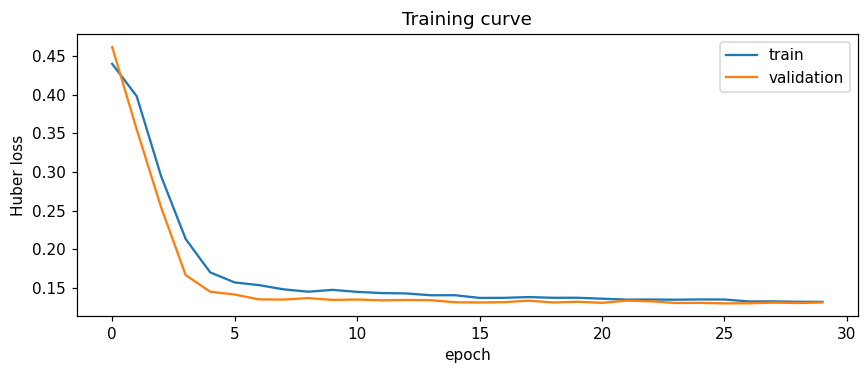

In [23]:
cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5),
]
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30, batch_size=16, callbacks=cbs, verbose=1,
)
print("Epochs run:", len(history.history["loss"]),
      "| best val loss: %.4f" % min(history.history["val_loss"]))

plt.figure(figsize=(8, 3.5))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("Huber loss"); plt.title("Training curve"); plt.legend()
plt.tight_layout(); plt.show()

## 9. Forecast the held-out test period (unseen)
Rolling-origin evaluation: every 7 days the model receives the **real** previous 28 days and forecasts the next 7. Blocks are stitched into one 56-day forecast. No test value is ever used to predict itself.
We also compute a **seasonal-naive baseline** (repeat the last observed week) to check that the LSTM actually adds value.

In [24]:
def inverse_to_views(arr_scaled):
    shp = arr_scaled.shape
    log_vals = scaler.inverse_transform(arr_scaled.reshape(-1, N_SERIES)).reshape(shp)
    return np.clip(np.expm1(log_vals), 0, None)

origins = list(range(test_start, N_DAYS, HORIZON))
X_test = np.array([features[t-WINDOW:t] for t in origins], dtype="float32")

pred_scaled = model.predict(X_test, verbose=0)                  # (blocks, HORIZON, N_SERIES)
pred_test = inverse_to_views(pred_scaled).reshape(-1, N_SERIES)  # (TEST_DAYS, N_SERIES)

# Seasonal-naive baseline: last week's actual values
base_test = np.vstack([ts_clean.values[t-HORIZON:t] for t in origins])

actual_test = ts_clean.values[test_start:]
test_dates = dates[test_start:]
print(pred_test.shape, actual_test.shape)

(56, 5) (56, 5)


## 10. Evaluation: MAE and RMSE (in real page-view units)

In [25]:
def mae_rmse(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred), np.sqrt(mean_squared_error(y_true, y_pred))

rows = []
for i, name in enumerate(ts_clean.columns):
    m, r = mae_rmse(actual_test[:, i], pred_test[:, i])
    mb, rb = mae_rmse(actual_test[:, i], base_test[:, i])
    rows.append([name, m, r, mb, rb])
m, r = mae_rmse(actual_test, pred_test)
mb, rb = mae_rmse(actual_test, base_test)
rows.append(["ALL (overall)", m, r, mb, rb])

results = pd.DataFrame(rows, columns=["Article", "LSTM MAE", "LSTM RMSE", "Naive MAE", "Naive RMSE"]).round(1)
display(results)

print(f"Overall LSTM  -> MAE {m:,.1f} | RMSE {r:,.1f}")
print(f"Seasonal naive -> MAE {mb:,.1f} | RMSE {rb:,.1f}")
print(f"MAE improvement vs baseline: {100*(mb-m)/mb:.1f}%")

,Article,LSTM MAE,LSTM RMSE,Naive MAE,Naive RMSE
0,Article_83_wikipedia.org_zh,52.6,66.4,77.9,99.7
1,Article_53_wikipedia.org_zh,268.8,345.9,362.7,486.3
2,Article_70_wikipedia.org_en,281.1,358.7,383.8,484.6
3,Article_45_wikipedia.org_en,442.6,552.2,566.6,735.9
4,Article_44_wikipedia.org_ja,583.7,739.1,930.5,1135.8
5,ALL (overall),325.8,469.9,464.3,680.1


Overall LSTM  -> MAE 325.8 | RMSE 469.9
Seasonal naive -> MAE 464.3 | RMSE 680.1
MAE improvement vs baseline: 29.8%


In [28]:
def compute_mape_smape(y_true, y_pred):
    # Avoid division by zero by adding a small epsilon where y_true is exactly 0
    eps = 1.0
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + eps))) * 100
    smape = np.mean(2.0 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred) + eps)) * 100
    return mape, smape

accuracy_rows = []
for i, name in enumerate(ts_clean.columns):
    mape, smape = compute_mape_smape(actual_test[:, i], pred_test[:, i])
    mape_b, smape_b = compute_mape_smape(actual_test[:, i], base_test[:, i])
    accuracy_rows.append([name, f"{100 - mape:.1f}%", f"{100 - smape:.1f}%", f"{100 - mape_b:.1f}%", f"{100 - smape_b:.1f}%"])

overall_mape, overall_smape = compute_mape_smape(actual_test, pred_test)
overall_mape_b, overall_smape_b = compute_mape_smape(actual_test, base_test)
accuracy_rows.append(["ALL (overall)", f"{100 - overall_mape:.1f}%", f"{100 - overall_smape:.1f}%", f"{100 - overall_mape_b:.1f}%", f"{100 - overall_smape_b:.1f}%"])

accuracy_results = pd.DataFrame(accuracy_rows, columns=[
    "Article", "LSTM Accuracy (100-MAPE)", "LSTM Accuracy (100-SMAPE)",
    "Naive Accuracy (100-MAPE)", "Naive Accuracy (100-SMAPE)"
])
display(accuracy_results)

,Article,LSTM Accuracy (100-MAPE),LSTM Accuracy (100-SMAPE),Naive Accuracy (100-MAPE),Naive Accuracy (100-SMAPE)
0,Article_83_wikipedia.org_zh,92.0%,92.1%,88.2%,88.3%
1,Article_53_wikipedia.org_zh,89.8%,89.9%,86.3%,86.4%
2,Article_70_wikipedia.org_en,91.1%,91.1%,87.4%,87.5%
3,Article_45_wikipedia.org_en,91.9%,91.9%,89.4%,89.6%
4,Article_44_wikipedia.org_ja,91.6%,91.7%,86.9%,86.9%
5,ALL (overall),91.3%,91.4%,87.6%,87.8%


## 11. Actual vs. predicted on the unseen test dates

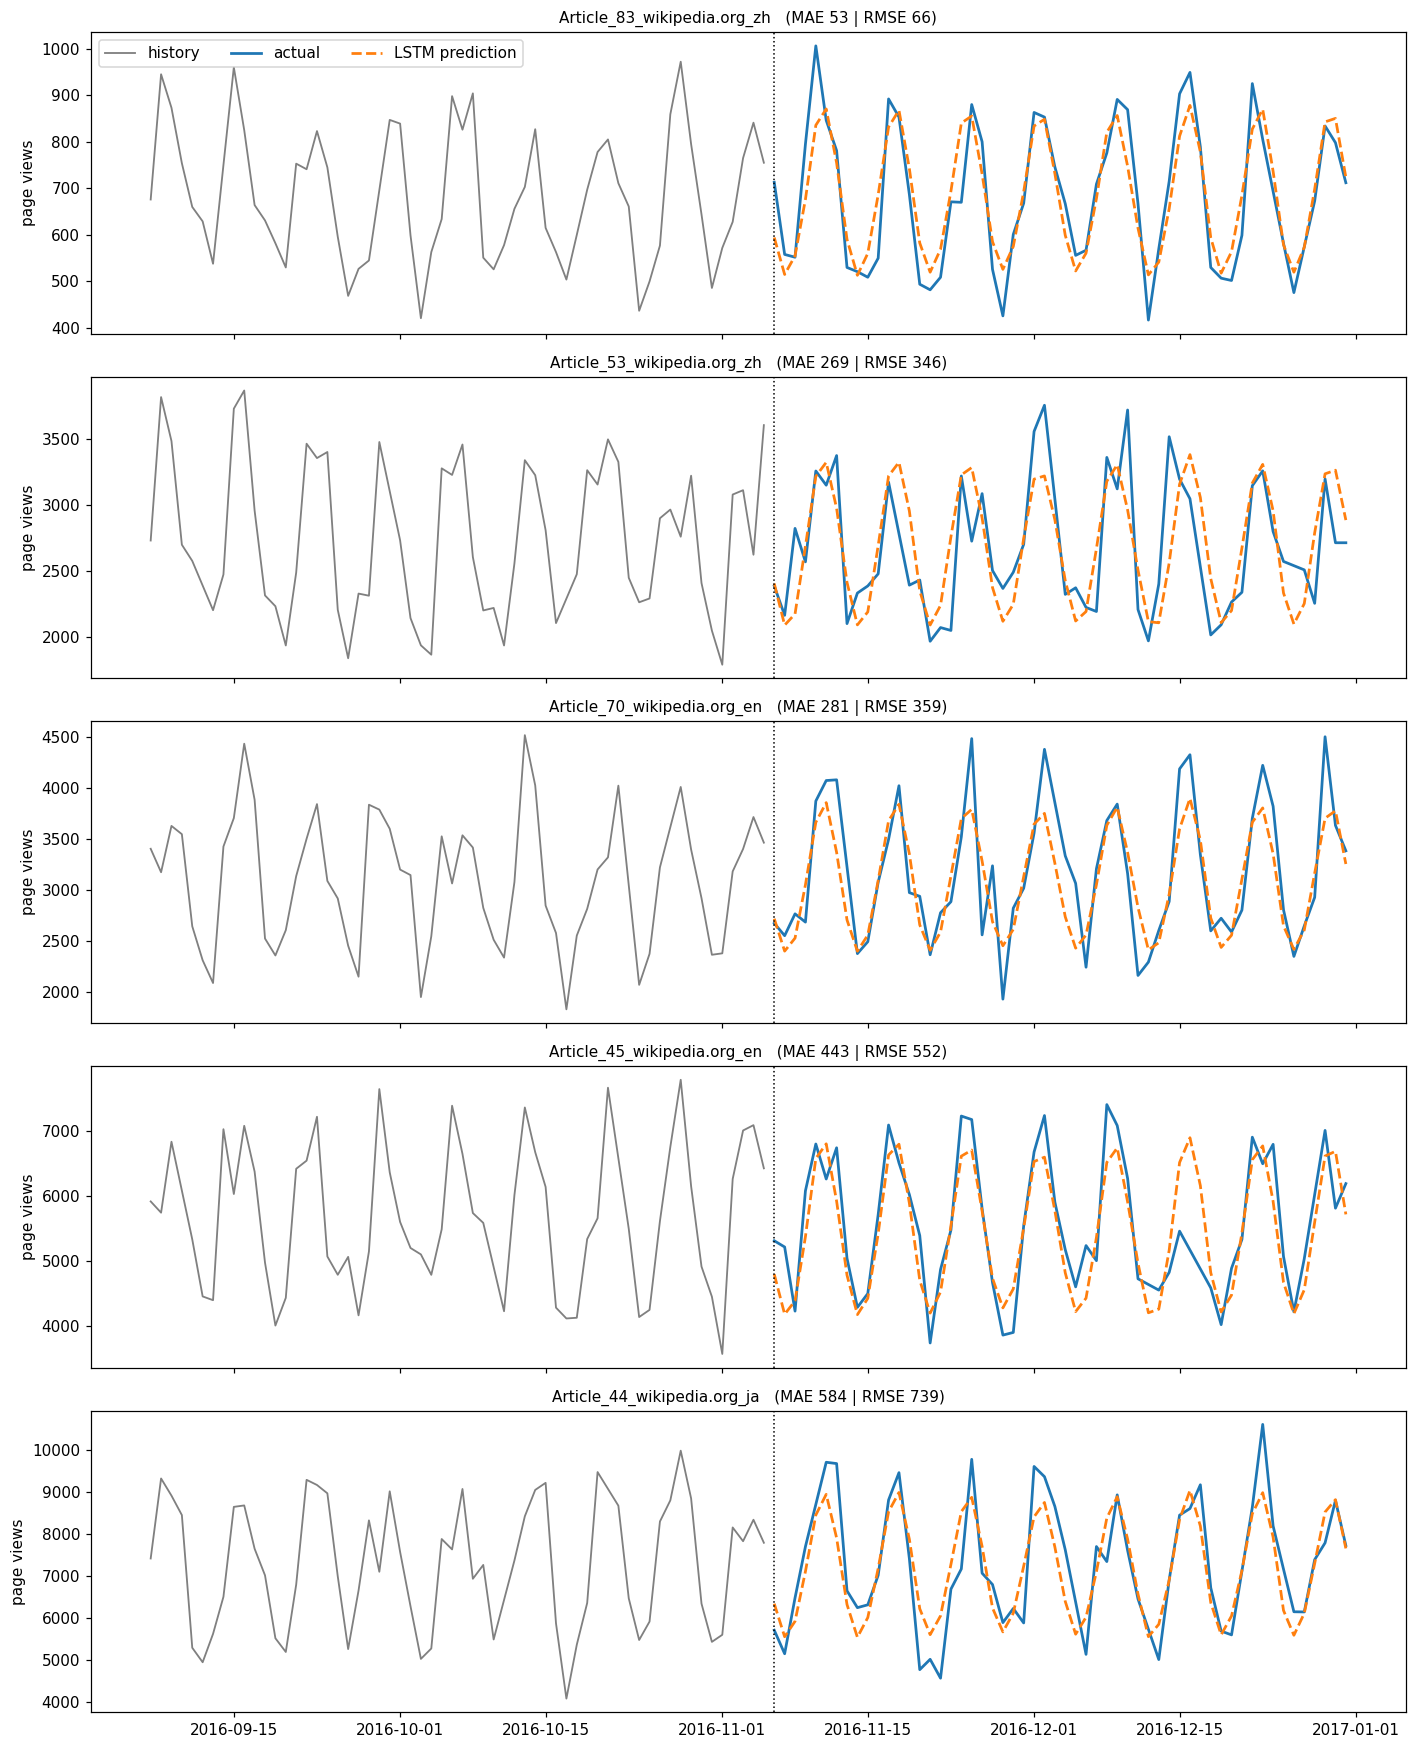

In [26]:
ctx = 60   # days of history to show before the test period
fig, axes = plt.subplots(N_SERIES, 1, figsize=(13, 3.2*N_SERIES), sharex=True)
for i, (ax, name) in enumerate(zip(axes, ts_clean.columns)):
    ax.plot(dates[test_start-ctx:test_start], ts_clean.values[test_start-ctx:test_start, i],
            color="gray", lw=1.2, label="history")
    ax.plot(test_dates, actual_test[:, i], color="tab:blue", lw=1.8, label="actual")
    ax.plot(test_dates, pred_test[:, i], color="tab:orange", lw=1.8, ls="--", label="LSTM prediction")
    ax.axvline(test_dates[0], color="k", ls=":", lw=1)
    mae_i, rmse_i = mae_rmse(actual_test[:, i], pred_test[:, i])
    ax.set_title(f"{name}   (MAE {mae_i:,.0f} | RMSE {rmse_i:,.0f})", fontsize=10)
    ax.set_ylabel("page views")
axes[0].legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

## 12. Demonstration on completely unseen future dates
The dataset ends on the last date above, so there is no ground truth for what follows. Here the model forecasts the **next 28 days** by feeding each 7-day forecast back as input (recursive multi-step). This is how it would be used operationally for capacity planning; expect uncertainty to grow with the horizon.

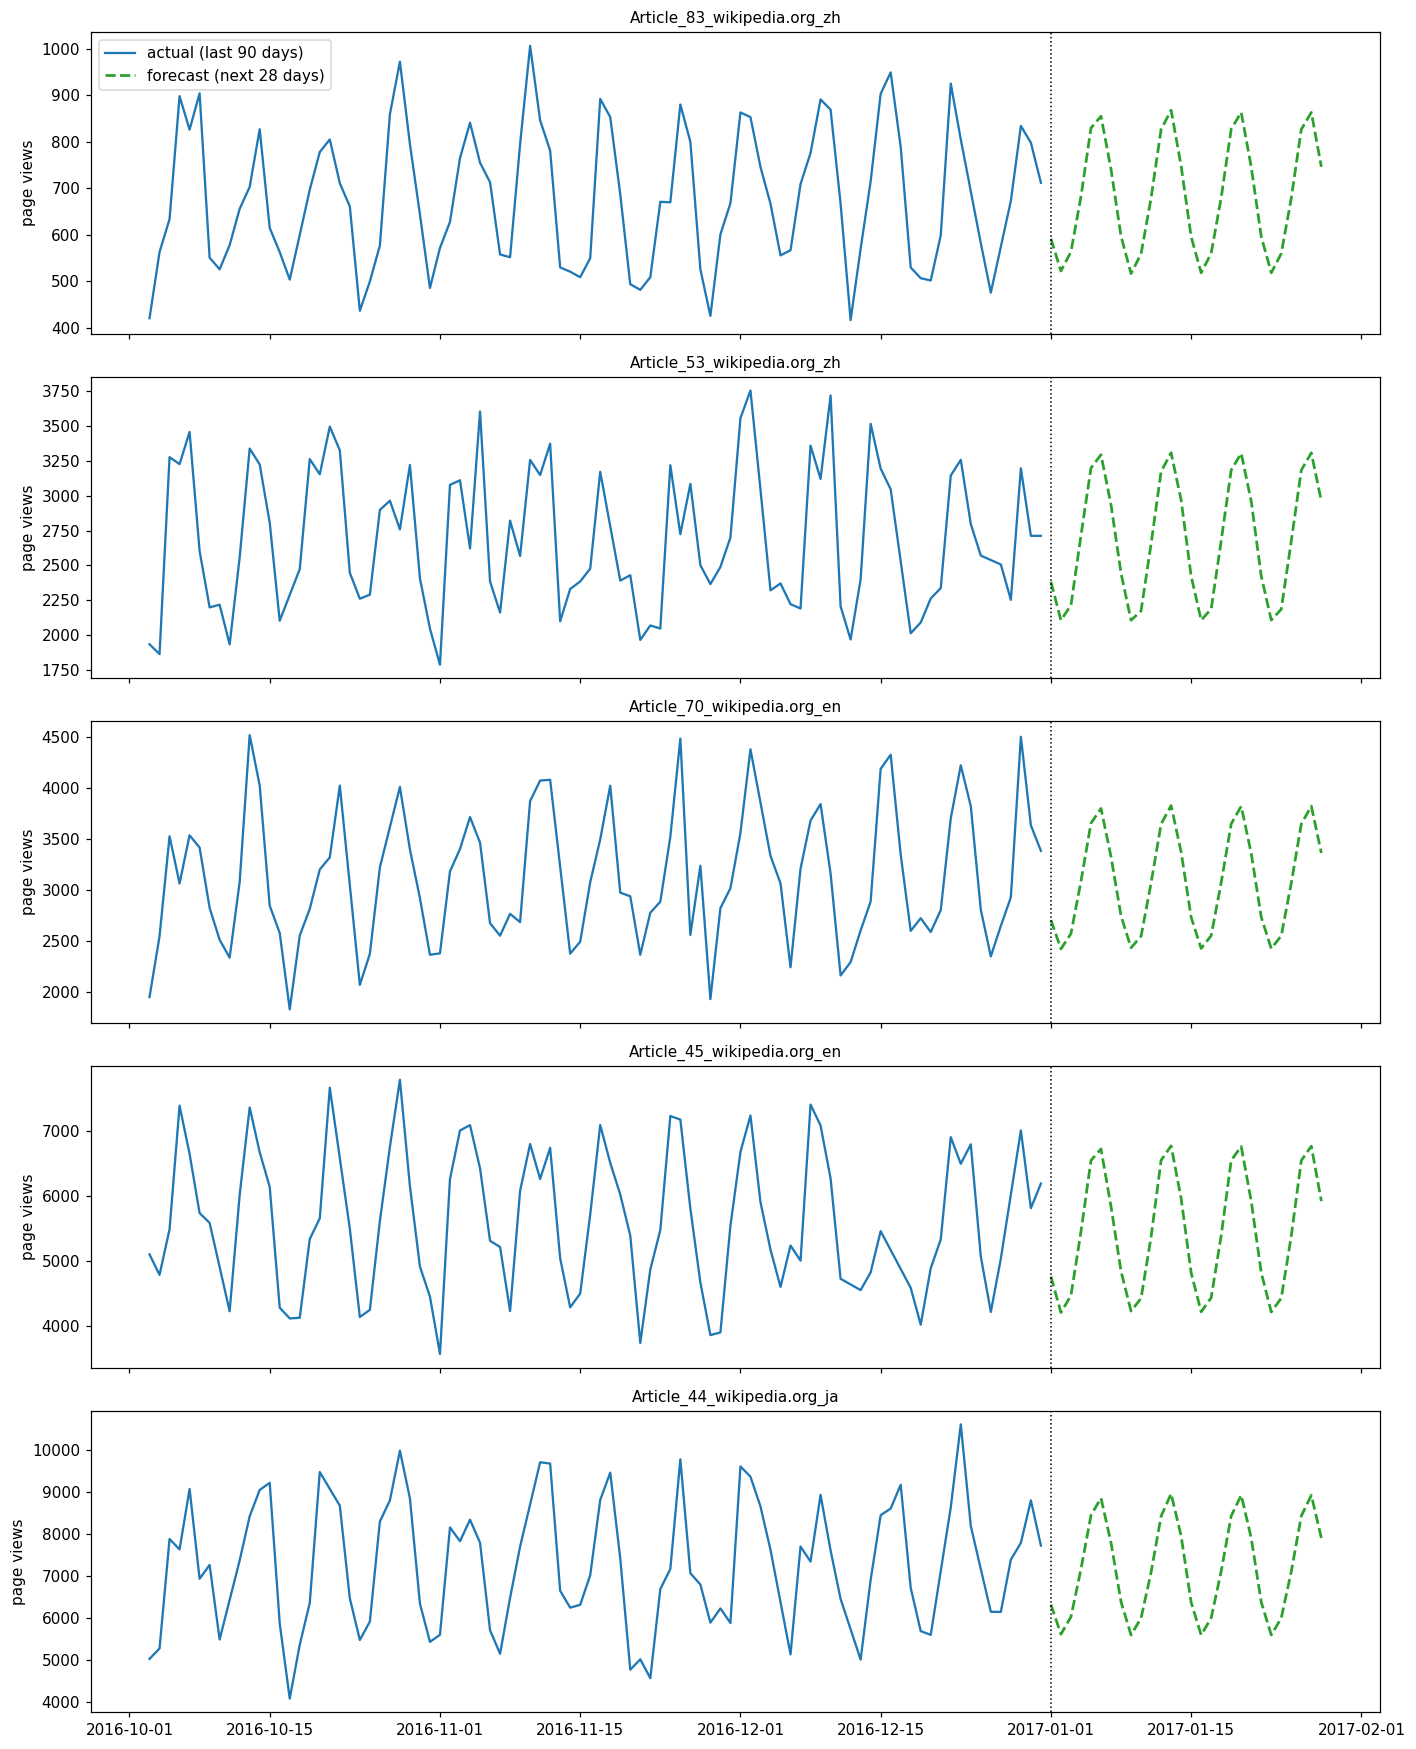

,Article_83_wikipedia.org_zh,Article_53_wikipedia.org_zh,Article_70_wikipedia.org_en,Article_45_wikipedia.org_en,Article_44_wikipedia.org_ja
date,,,,,
2017-01-01,592,2383,2701,4757,6312
2017-01-02,522,2106,2418,4204,5606
2017-01-03,564,2214,2568,4464,6021
2017-01-04,682,2715,3081,5446,7159
2017-01-05,830,3200,3651,6542,8443
2017-01-06,855,3296,3795,6719,8853
2017-01-07,741,2936,3323,5834,7788
2017-01-08,597,2444,2742,4838,6381
2017-01-09,517,2107,2430,4226,5586


In [27]:
FUTURE_DAYS = 28
future_dates = pd.date_range(dates[-1] + pd.Timedelta(days=1), periods=FUTURE_DAYS)
future_cal = calendar_features(future_dates)

hist = features.copy()
future_scaled = []
for b in range(FUTURE_DAYS // HORIZON):
    x = hist[-WINDOW:][None].astype("float32")
    p = model.predict(x, verbose=0)[0]                       # (HORIZON, N_SERIES)
    cal = future_cal[b*HORIZON:(b+1)*HORIZON]
    hist = np.vstack([hist, np.hstack([p, cal])])
    future_scaled.append(p)

future_pred = inverse_to_views(np.vstack(future_scaled))      # (FUTURE_DAYS, N_SERIES)

fig, axes = plt.subplots(N_SERIES, 1, figsize=(13, 3.2*N_SERIES), sharex=True)
for i, (ax, name) in enumerate(zip(axes, ts_clean.columns)):
    ax.plot(dates[-90:], ts_clean.values[-90:, i], color="tab:blue", lw=1.5, label="actual (last 90 days)")
    ax.plot(future_dates, future_pred[:, i], color="tab:green", lw=1.8, ls="--", label="forecast (next 28 days)")
    ax.axvline(future_dates[0], color="k", ls=":", lw=1)
    ax.set_title(name, fontsize=10); ax.set_ylabel("page views")
axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

forecast_table = pd.DataFrame(np.round(future_pred).astype(int), index=future_dates, columns=ts_clean.columns)
forecast_table.index.name = "date"
display(forecast_table.head(10))

## 13. Summary and next steps
- **Missing values** were time-interpolated (not zero-filled), edges filled with the nearest value.
- A **log1p + standardisation** pipeline (fit on train only) stabilised the heavy-tailed series.
- A **2-layer LSTM** trained on chronological 28-day windows forecasts 7 days ahead for all five articles.
- Performance is reported with **MAE and RMSE** on a held-out, unseen 56-day test period and compared with a seasonal-naive baseline. RMSE > MAE signals the effect of traffic spikes, which matter for server sizing.
- **For production:** retrain on all data (train+val+test) before forecasting the future, add a safety margin (e.g. forecast + k x RMSE) when provisioning servers, and consider GRU/Transformer or adding holiday/event features and prediction intervals.